In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../dataset/processed/cleaned_telco.csv")

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


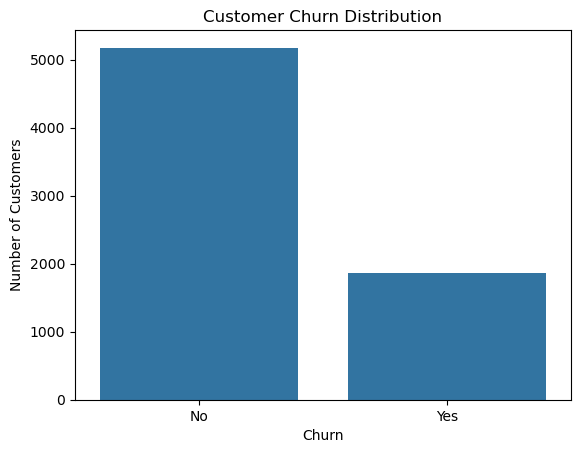

In [4]:
sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

In [5]:
churn_percentage = df["Churn"].value_counts(normalize=True) * 100

print(churn_percentage)

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [6]:
pd.crosstab(df["Contract"], df["Churn"])

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


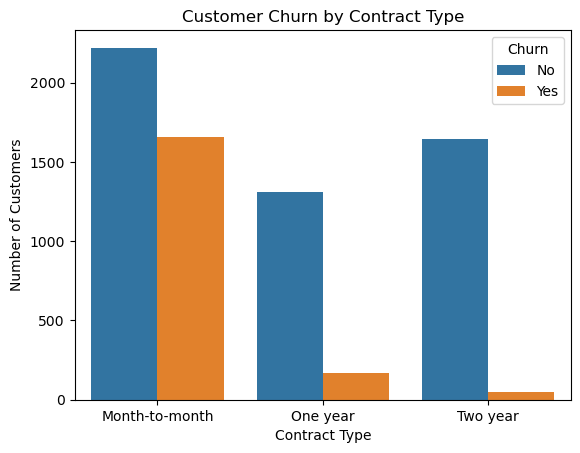

In [7]:
sns.countplot(data=df, x="Contract", hue="Churn")

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.show()

In [8]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

contract_churn

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


In [9]:
contract_churn["Yes"].sort_values(ascending=False)

Contract
Month-to-month    42.709677
One year          11.269518
Two year           2.831858
Name: Yes, dtype: float64

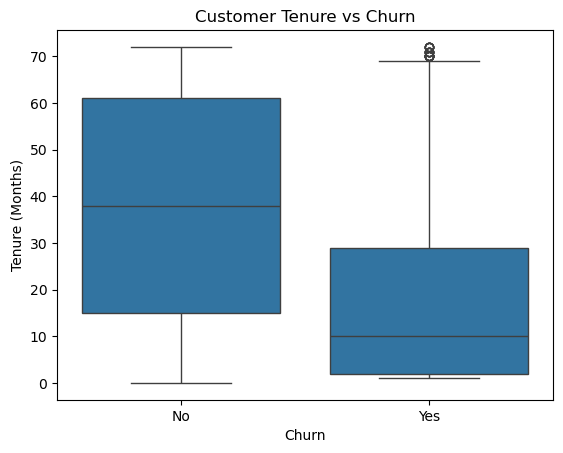

In [10]:
sns.boxplot(data=df, x="Churn", y="tenure")

plt.title("Customer Tenure vs Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")

plt.show()

In [11]:
df.groupby("Churn")["tenure"].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,37.569965,24.113777,0.0,15.0,38.0,61.0,72.0
Yes,1869.0,17.979133,19.531123,1.0,2.0,10.0,29.0,72.0


In [ ]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

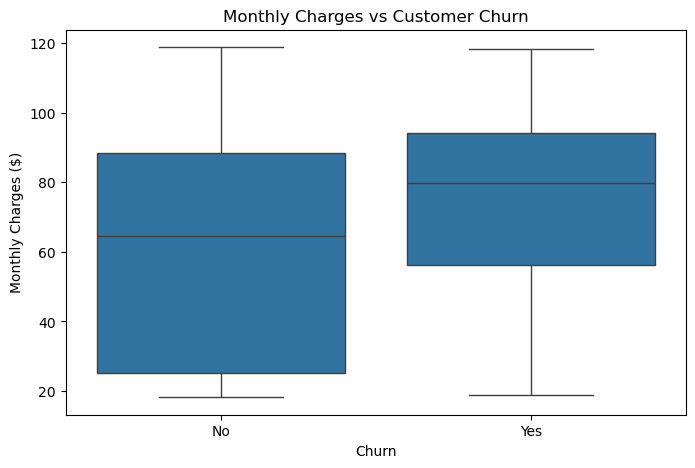

In [12]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges vs Customer Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges ($)")

plt.show()

In [13]:
print("Monthly Charges Analysis:")
print(df.groupby("Churn")["MonthlyCharges"].describe())

Monthly Charges Analysis:
        count       mean        std    min    25%     50%   75%     max
Churn                                                                  
No     5174.0  61.265124  31.092648  18.25  25.10  64.425  88.4  118.75
Yes    1869.0  74.441332  24.666053  18.85  56.15  79.650  94.2  118.35


Internet Service vs Churn:
Churn              No   Yes
InternetService            
DSL              1962   459
Fiber optic      1799  1297
No               1413   113

Churn Percentage:
Churn               No    Yes
InternetService              
DSL              81.04  18.96
Fiber optic      58.11  41.89
No               92.60   7.40


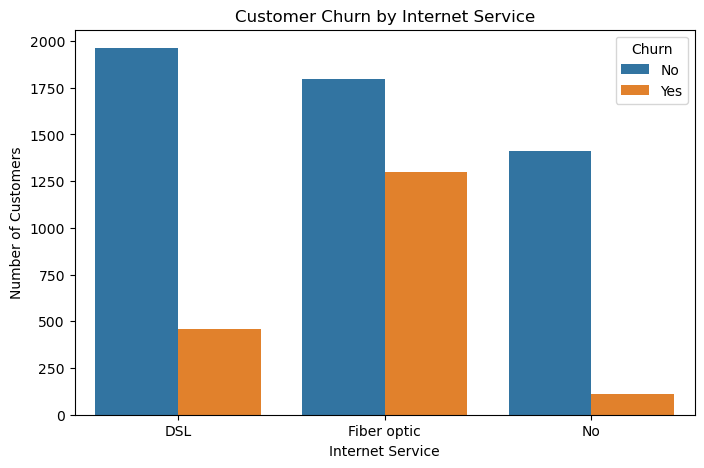

In [14]:
# 1. Numerical analysis
print("Internet Service vs Churn:")
print(pd.crosstab(
    df["InternetService"],
    df["Churn"]
))

# 2. Calculate churn percentages
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

print("\nChurn Percentage:")
print(internet_churn.round(2))

# 3. Visual analysis
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="InternetService",
    hue="Churn"
)

plt.title("Customer Churn by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")

plt.show()

Payment Method vs Churn:
Churn                        No   Yes
PaymentMethod                        
Bank transfer (automatic)  1286   258
Credit card (automatic)    1290   232
Electronic check           1294  1071
Mailed check               1304   308

Churn Percentage:
Churn                         No    Yes
PaymentMethod                          
Bank transfer (automatic)  83.29  16.71
Credit card (automatic)    84.76  15.24
Electronic check           54.71  45.29
Mailed check               80.89  19.11


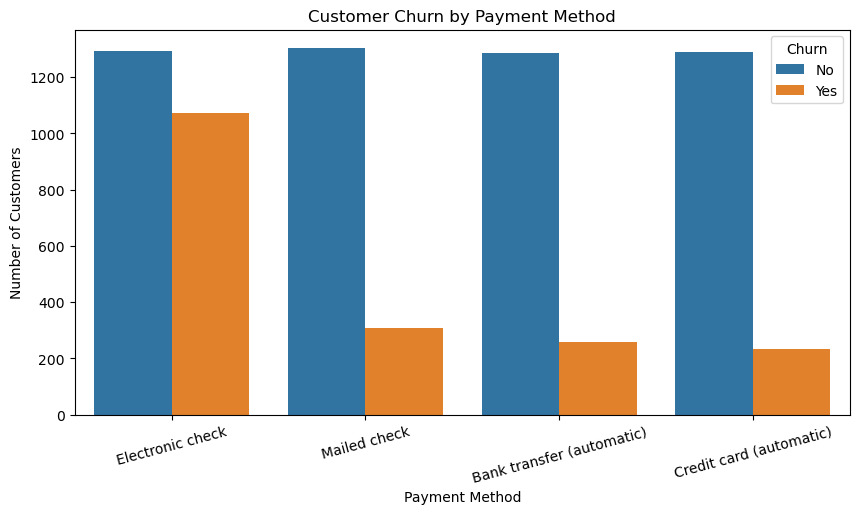

In [17]:
# 1. Numerical analysis
print("Payment Method vs Churn:")

print(pd.crosstab(
    df["PaymentMethod"],
    df["Churn"]
))

# 2. Calculate churn percentages
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

print("\nChurn Percentage:")
print(payment_churn.round(2))

# 3. Visual analysis
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="PaymentMethod",
    hue="Churn"
)

plt.title("Customer Churn by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)

plt.show()

Dependents vs Churn:
Churn         No   Yes
Dependents            
No          3390  1543
Yes         1784   326

Churn Percentage:
Churn          No    Yes
Dependents              
No          68.72  31.28
Yes         84.55  15.45


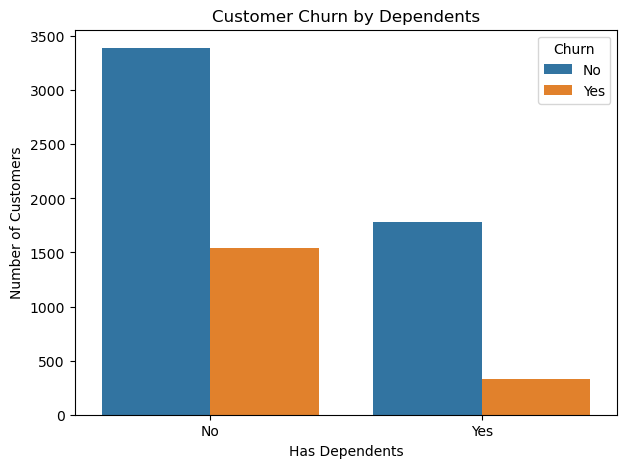

In [18]:
# 1. Numerical analysis
print("Dependents vs Churn:")

print(pd.crosstab(
    df["Dependents"],
    df["Churn"]
))

# 2. Calculate churn percentages
dependents_churn = pd.crosstab(
    df["Dependents"],
    df["Churn"],
    normalize="index"
) * 100

print("\nChurn Percentage:")
print(dependents_churn.round(2))

# 3. Visual analysis
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Dependents",
    hue="Churn"
)

plt.title("Customer Churn by Dependents")
plt.xlabel("Has Dependents")
plt.ylabel("Number of Customers")

plt.show()

Partner Status vs Churn:
Churn      No   Yes
Partner            
No       2441  1200
Yes      2733   669

Churn Percentage:
Churn       No    Yes
Partner              
No       67.04  32.96
Yes      80.34  19.66


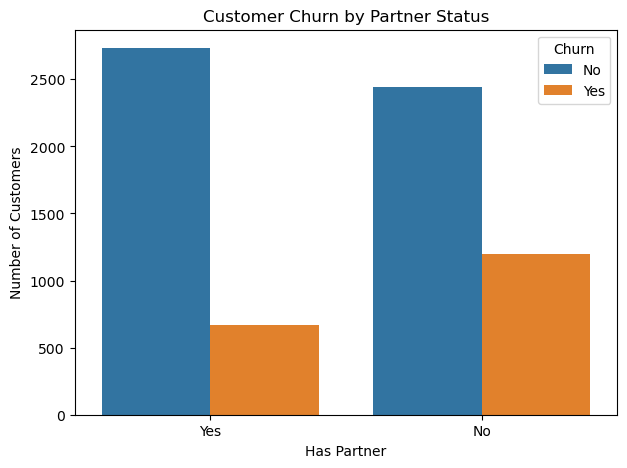

In [19]:
# 1. Numerical analysis
print("Partner Status vs Churn:")

print(pd.crosstab(
    df["Partner"],
    df["Churn"]
))

# 2. Calculate churn percentages
partner_churn = pd.crosstab(
    df["Partner"],
    df["Churn"],
    normalize="index"
) * 100

print("\nChurn Percentage:")
print(partner_churn.round(2))

# 3. Visual analysis
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Partner",
    hue="Churn"
)

plt.title("Customer Churn by Partner Status")
plt.xlabel("Has Partner")
plt.ylabel("Number of Customers")

plt.show()

Senior Citizen vs Churn:
Churn            No   Yes
SeniorCitizen            
0              4508  1393
1               666   476

Churn Percentage:
Churn             No    Yes
SeniorCitizen              
0              76.39  23.61
1              58.32  41.68


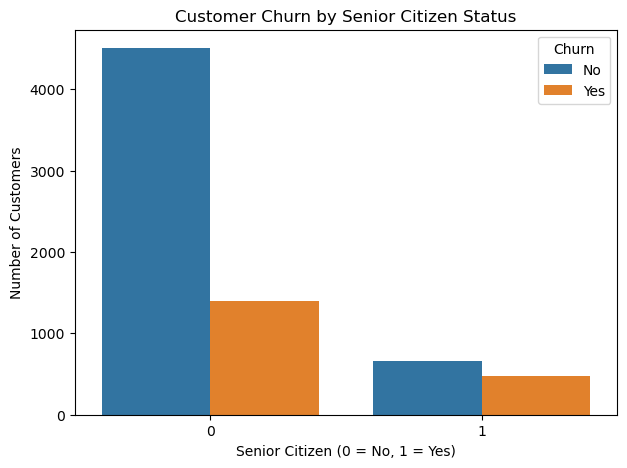

In [20]:
# 1. Numerical analysis
print("Senior Citizen vs Churn:")

print(pd.crosstab(
    df["SeniorCitizen"],
    df["Churn"]
))

# 2. Calculate churn percentages
senior_churn = pd.crosstab(
    df["SeniorCitizen"],
    df["Churn"],
    normalize="index"
) * 100

print("\nChurn Percentage:")
print(senior_churn.round(2))

# 3. Visual analysis
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="SeniorCitizen",
    hue="Churn"
)

plt.title("Customer Churn by Senior Citizen Status")
plt.xlabel("Senior Citizen (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")

plt.show()

Online Security vs Churn:
Churn                  No   Yes
OnlineSecurity                 
No                   2037  1461
No internet service  1413   113
Yes                  1724   295

Churn Percentage:
Churn                   No    Yes
OnlineSecurity                   
No                   58.23  41.77
No internet service  92.60   7.40
Yes                  85.39  14.61


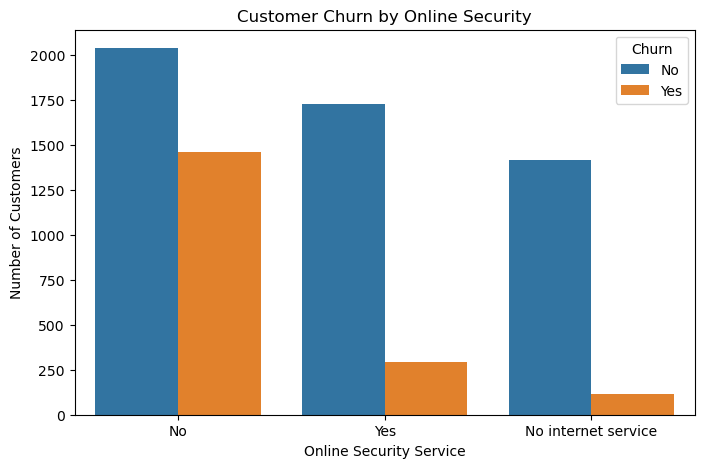

In [21]:
# 1. Numerical analysis
print("Online Security vs Churn:")

print(pd.crosstab(
    df["OnlineSecurity"],
    df["Churn"]
))

# 2. Calculate churn percentages
security_churn = pd.crosstab(
    df["OnlineSecurity"],
    df["Churn"],
    normalize="index"
) * 100

print("\nChurn Percentage:")
print(security_churn.round(2))

# 3. Visual analysis
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="OnlineSecurity",
    hue="Churn"
)

plt.title("Customer Churn by Online Security")
plt.xlabel("Online Security Service")
plt.ylabel("Number of Customers")

plt.show()

Tech Support vs Churn:
Churn                  No   Yes
TechSupport                    
No                   2027  1446
No internet service  1413   113
Yes                  1734   310

Churn Percentage:
Churn                   No    Yes
TechSupport                      
No                   58.36  41.64
No internet service  92.60   7.40
Yes                  84.83  15.17


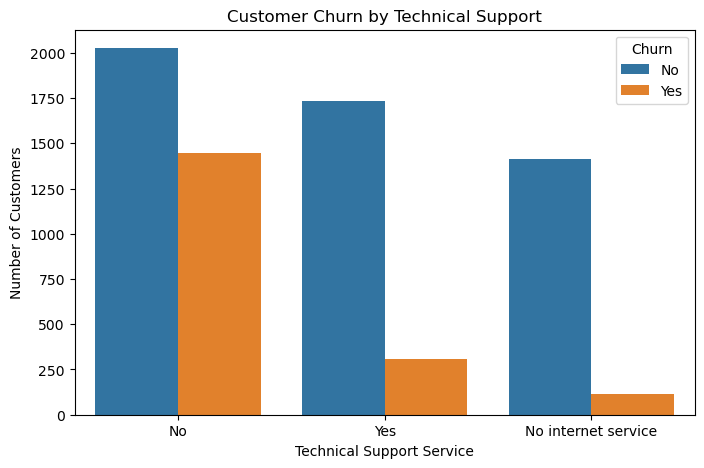

In [22]:
# 1. Numerical analysis
print("Tech Support vs Churn:")

print(pd.crosstab(
    df["TechSupport"],
    df["Churn"]
))

# 2. Calculate churn percentages
support_churn = pd.crosstab(
    df["TechSupport"],
    df["Churn"],
    normalize="index"
) * 100

print("\nChurn Percentage:")
print(support_churn.round(2))

# 3. Visual analysis
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="TechSupport",
    hue="Churn"
)

plt.title("Customer Churn by Technical Support")
plt.xlabel("Technical Support Service")
plt.ylabel("Number of Customers")

plt.show()

Paperless Billing vs Churn:
Churn               No   Yes
PaperlessBilling            
No                2403   469
Yes               2771  1400

Churn Percentage:
Churn                No    Yes
PaperlessBilling              
No                83.67  16.33
Yes               66.43  33.57


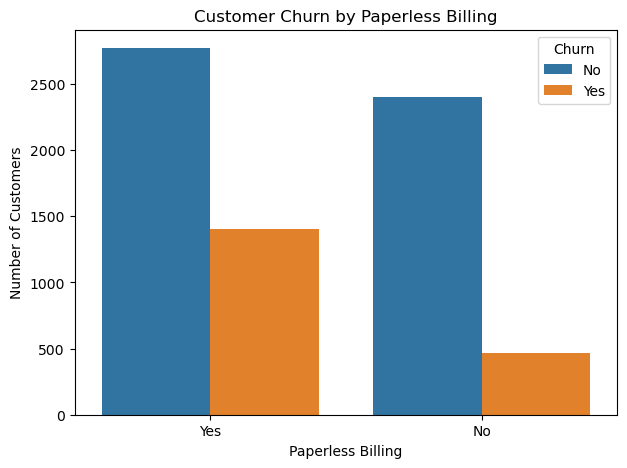

In [23]:
# 1. Numerical analysis
print("Paperless Billing vs Churn:")

print(pd.crosstab(
    df["PaperlessBilling"],
    df["Churn"]
))

# 2. Calculate churn percentages
billing_churn = pd.crosstab(
    df["PaperlessBilling"],
    df["Churn"],
    normalize="index"
) * 100

print("\nChurn Percentage:")
print(billing_churn.round(2))

# 3. Visual analysis
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="PaperlessBilling",
    hue="Churn"
)

plt.title("Customer Churn by Paperless Billing")
plt.xlabel("Paperless Billing")
plt.ylabel("Number of Customers")

plt.show()

Online Backup vs Churn:
Churn                  No   Yes
OnlineBackup                   
No                   1855  1233
No internet service  1413   113
Yes                  1906   523

Churn Percentage:
Churn                   No    Yes
OnlineBackup                     
No                   60.07  39.93
No internet service  92.60   7.40
Yes                  78.47  21.53


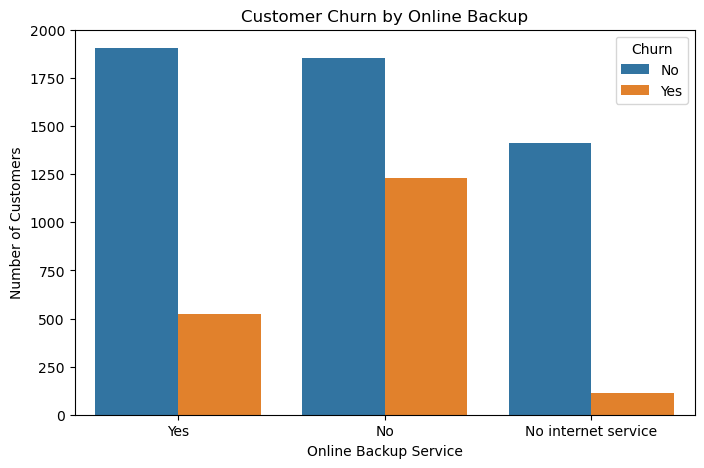

In [24]:
# 1. Numerical analysis
print("Online Backup vs Churn:")

print(pd.crosstab(
    df["OnlineBackup"],
    df["Churn"]
))

# 2. Calculate churn percentages
backup_churn = pd.crosstab(
    df["OnlineBackup"],
    df["Churn"],
    normalize="index"
) * 100

print("\nChurn Percentage:")
print(backup_churn.round(2))

# 3. Visual analysis
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="OnlineBackup",
    hue="Churn"
)

plt.title("Customer Churn by Online Backup")
plt.xlabel("Online Backup Service")
plt.ylabel("Number of Customers")

plt.show()

Paperless Billing vs Churn:
Churn               No   Yes
PaperlessBilling            
No                2403   469
Yes               2771  1400

Churn Percentage:
Churn                No    Yes
PaperlessBilling              
No                83.67  16.33
Yes               66.43  33.57


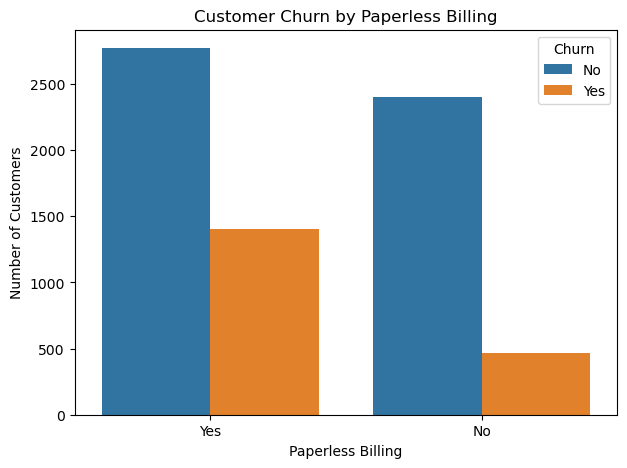

In [ ]:
# 1. Numerical analysis
print("Paperless Billing vs Churn:")

print(pd.crosstab(
    df["PaperlessBilling"],
    df["Churn"]
))

# 2. Calculate churn percentages
billing_churn = pd.crosstab(
    df["PaperlessBilling"],
    df["Churn"],
    normalize="index"
) * 100

print("\nChurn Percentage:")
print(billing_churn.round(2))

# 3. Visual analysis
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="PaperlessBilling",
    hue="Churn"
)

plt.title("Customer Churn by Paperless Billing")
plt.xlabel("Paperless Billing")
plt.ylabel("Number of Customers")

plt.show()

Device Protection vs Churn:
Churn                  No   Yes
DeviceProtection               
No                   1884  1211
No internet service  1413   113
Yes                  1877   545

Churn Percentage:
Churn                   No    Yes
DeviceProtection                 
No                   60.87  39.13
No internet service  92.60   7.40
Yes                  77.50  22.50


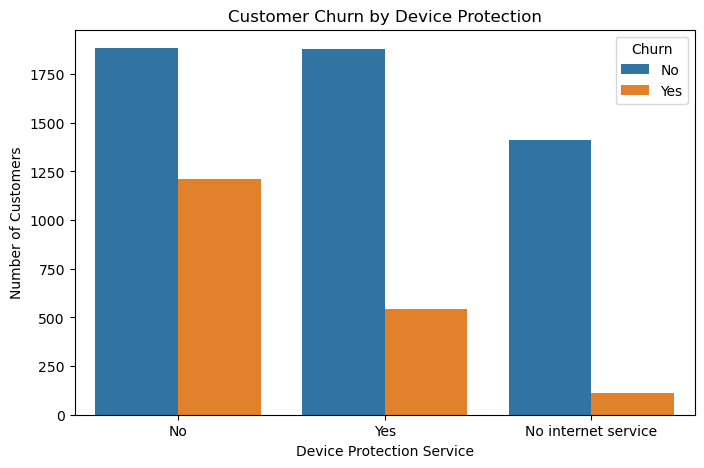

In [25]:
# 1. Numerical analysis
print("Device Protection vs Churn:")

print(pd.crosstab(
    df["DeviceProtection"],
    df["Churn"]
))

# 2. Calculate churn percentages
device_churn = pd.crosstab(
    df["DeviceProtection"],
    df["Churn"],
    normalize="index"
) * 100

print("\nChurn Percentage:")
print(device_churn.round(2))

# 3. Visual analysis
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="DeviceProtection",
    hue="Churn"
)

plt.title("Customer Churn by Device Protection")
plt.xlabel("Device Protection Service")
plt.ylabel("Number of Customers")

plt.show()

Multiple Lines vs Churn:
Churn               No  Yes
MultipleLines              
No                2541  849
No phone service   512  170
Yes               2121  850

Churn Percentage:
Churn                No    Yes
MultipleLines                 
No                74.96  25.04
No phone service  75.07  24.93
Yes               71.39  28.61


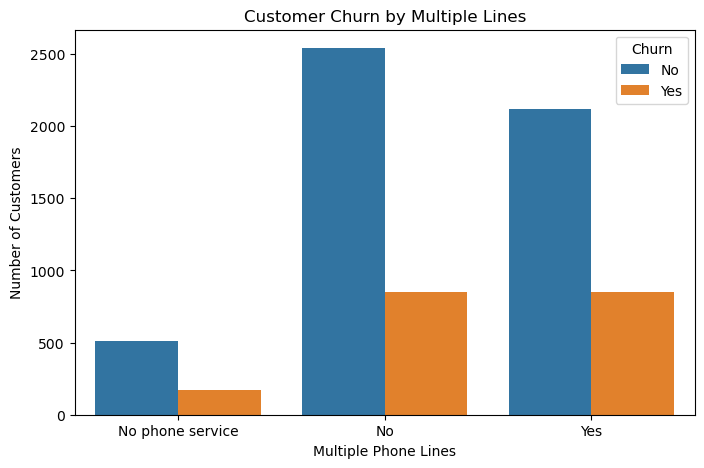

In [26]:
# 1. Numerical analysis
print("Multiple Lines vs Churn:")

print(pd.crosstab(
    df["MultipleLines"],
    df["Churn"]
))

# 2. Calculate churn percentages
multiple_lines_churn = pd.crosstab(
    df["MultipleLines"],
    df["Churn"],
    normalize="index"
) * 100

print("\nChurn Percentage:")
print(multiple_lines_churn.round(2))

# 3. Visual analysis
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="MultipleLines",
    hue="Churn"
)

plt.title("Customer Churn by Multiple Lines")
plt.xlabel("Multiple Phone Lines")
plt.ylabel("Number of Customers")

plt.show()

Streaming TV vs Churn:
Churn                  No  Yes
StreamingTV                   
No                   1868  942
No internet service  1413  113
Yes                  1893  814

Churn Percentage:
Churn                   No    Yes
StreamingTV                      
No                   66.48  33.52
No internet service  92.60   7.40
Yes                  69.93  30.07


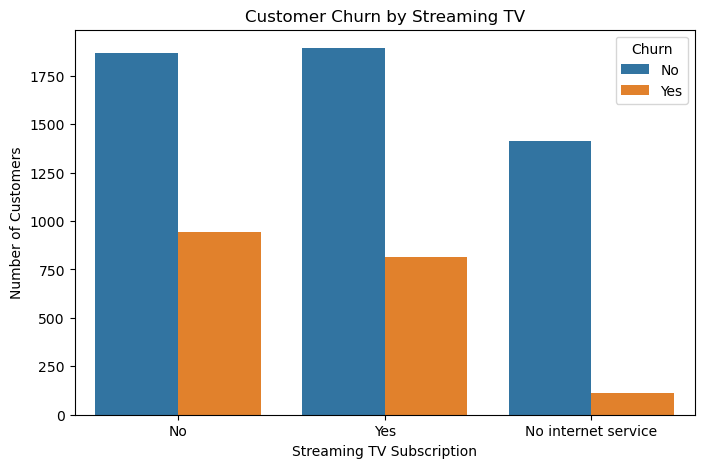

In [27]:
# 1. Numerical analysis
print("Streaming TV vs Churn:")

print(pd.crosstab(
    df["StreamingTV"],
    df["Churn"]
))

# 2. Calculate churn percentages
streaming_tv_churn = pd.crosstab(
    df["StreamingTV"],
    df["Churn"],
    normalize="index"
) * 100

print("\nChurn Percentage:")
print(streaming_tv_churn.round(2))

# 3. Visual analysis
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="StreamingTV",
    hue="Churn"
)

plt.title("Customer Churn by Streaming TV")
plt.xlabel("Streaming TV Subscription")
plt.ylabel("Number of Customers")

plt.show()

In [28]:
print("Streaming Movies vs Churn:")

print(pd.crosstab(
    df["StreamingMovies"],
    df["Churn"]
))

streaming_movies_churn = pd.crosstab(
    df["StreamingMovies"],
    df["Churn"],
    normalize="index"
) * 100

print("\nChurn Percentage:")
print(streaming_movies_churn.round(2))

Streaming Movies vs Churn:
Churn                  No  Yes
StreamingMovies               
No                   1847  938
No internet service  1413  113
Yes                  1914  818

Churn Percentage:
Churn                   No    Yes
StreamingMovies                  
No                   66.32  33.68
No internet service  92.60   7.40
Yes                  70.06  29.94
